# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

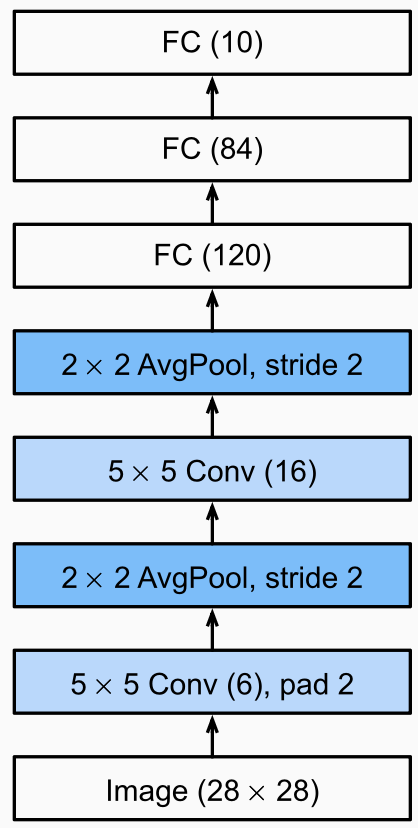

## **Data**

In [2]:
from pathlib import Path
import zipfile

import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# ===== Cấu hình chung (Kaggle) =====
KAGGLE_INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working")

IMG_SIZE = 64
BATCH = 32
SEED = 42

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def find_root(base):
    """Trả về thư mục cha của thư mục 'train' đầu tiên tìm thấy dưới base."""
    for p in sorted(base.rglob("train")):
        if p.is_dir():
            return p.parent
    return None


def locate_dataset():
    cands = [d for d in KAGGLE_INPUT.iterdir() if "vinafood21" in d.name.lower()]
    cands = cands or [KAGGLE_INPUT]

    for d in cands:
        root = find_root(d)
        if root is not None:
            return root

    for d in cands:
        for z in d.rglob("VinaFood21.zip"):
            out = WORK / "VinaFood21_extracted"
            if not out.exists():
                print("Đang giải nén", z, "->", out)
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(out)
            root = find_root(out)
            if root is not None:
                return root
    return None


DATA_ROOT = locate_dataset() or (KAGGLE_INPUT / "vinafood21")
HAS_DATA = (DATA_ROOT / "train").is_dir()
print("Tìm thấy dữ liệu:", HAS_DATA, "-", DATA_ROOT.resolve())


# ===== Transforms =====
def build_transforms(img_size=IMG_SIZE):
    # Train có augment, val/test không
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return train_tf, eval_tf


# ===== Loaders =====
def build_train_val_loaders(data_root=None, img_size=IMG_SIZE, batch_size=BATCH,
                            val_ratio=0.1, num_workers=2, seed=SEED):
    root = Path(data_root) if data_root is not None else DATA_ROOT
    if not (root / "train").is_dir():
        raise FileNotFoundError(f"Không thấy thư mục 'train' trong {root}")
    train_tf, eval_tf = build_transforms(img_size)

    if (root / "val").is_dir():
        train_ds = datasets.ImageFolder(root / "train", transform=train_tf)
        val_ds = datasets.ImageFolder(root / "val", transform=eval_tf)
        classes = train_ds.classes
    else:
        # Không có thư mục val thì tách một phần từ train
        # Hai ImageFolder trỏ cùng thư mục để val không bị augment
        full_train = datasets.ImageFolder(root / "train", transform=train_tf)
        full_eval = datasets.ImageFolder(root / "train", transform=eval_tf)
        g = torch.Generator().manual_seed(seed)
        idx = torch.randperm(len(full_train), generator=g).tolist()
        n_val = int(len(idx) * val_ratio)
        train_ds = Subset(full_train, idx[n_val:])
        val_ds = Subset(full_eval, idx[:n_val])
        classes = full_train.classes

    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers)
    val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers)
    return train_dl, val_dl, classes


def build_test_loader(data_root=None, img_size=IMG_SIZE, batch_size=BATCH,
                      num_workers=2):
    root = Path(data_root) if data_root is not None else DATA_ROOT
    _, eval_tf = build_transforms(img_size)
    test_ds = datasets.ImageFolder(root / "test", transform=eval_tf)
    test_dl = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                         num_workers=num_workers)
    return test_dl, test_ds.classes

Tìm thấy dữ liệu: True - /kaggle/input/datasets/ttrinh1805/vinafood21/VinaFood21


## **model LeNet**


In [3]:
import torch
import torch.nn as nn


class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21):
        super().__init__()
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = nn.AvgPool2d(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = nn.AvgPool2d(2, 2)

        n_flat = self._flat_dim(in_ch, img)
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)

    def _flat_dim(self, in_ch, img):
        # Dò số chiều sau S4 bằng một forward giả, tránh tính tay
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
        return int(z.flatten(1).shape[1])

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)


def n_params(module):
    return sum(p.numel() for p in module.parameters())


if __name__ == "__main__":
    # Chạy riêng file này để kiểm tra shape: python model.py
    m = LeNet5(in_ch=3, img=64, num_classes=21)
    x = torch.rand(2, 3, 64, 64)
    print("input :", tuple(x.shape))
    print("logits:", tuple(m(x).shape))
    print("params:", f"{n_params(m):,}")


input : (2, 3, 64, 64)
logits: (2, 21)
params: 339,421


## **Engine**

In [4]:
import torch
from sklearn.metrics import f1_score


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                     # bật dropout, BN dùng thống kê batch
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                      # tắt dropout, BN dùng thống kê tích luỹ
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()

    macro_f1 = f1_score(y_true, y_pred, average="macro")
    return running / total, correct / total, macro_f1, y_true, y_pred

## **Train LeNet**

device: cuda | số lớp: 21 | train: 9040 | val: 1004
LeNet5: 339,421 tham số


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.8129/0.1468   val 2.5745/0.2141  F1 0.1230  *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.5836/0.2114   val 2.4687/0.2361  F1 0.1602  *


...

epoch 18  train 1.9355/0.4008   val 2.1269/0.3625  F1 0.3309  *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19  train 1.9147/0.4108   val 2.1409/0.3556  F1 0.3259


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20  train 1.9056/0.4075   val 2.1800/0.3496  F1 0.3240


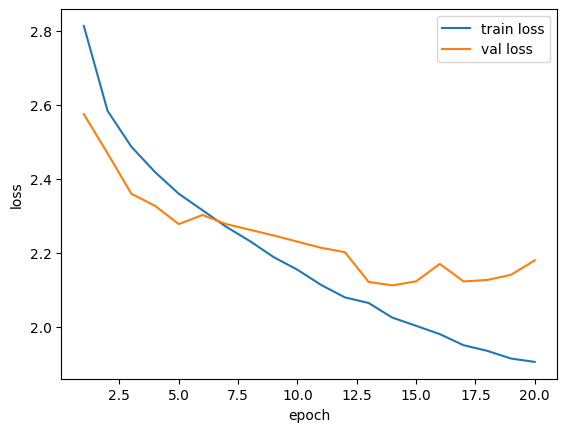


best val macro-F1: 0.3309 -> /kaggle/working/outputs/best.pt
test (epoch 18): loss 2.3841  acc 0.2999  macro-F1 0.2748


In [5]:
import argparse
import csv
from pathlib import Path

import torch
import torch.nn as nn

# data, model, engine đã được định nghĩa ở các ô trước nên không import lại


def get_args():
    p = argparse.ArgumentParser(description="Huấn luyện LeNet-5 trên VinaFood21")
    p.add_argument("--data_root", type=str, default=str(DATA_ROOT))
    p.add_argument("--img_size", type=int, default=IMG_SIZE)
    p.add_argument("--batch_size", type=int, default=BATCH)
    p.add_argument("--epochs", type=int, default=20)
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--num_workers", type=int, default=2)
    p.add_argument("--seed", type=int, default=SEED)
    default_out = "/kaggle/working/outputs" if Path("/kaggle/working").is_dir() else "outputs"
    p.add_argument("--out_dir", type=str, default=default_out)
    args, _ = p.parse_known_args()   # bỏ qua tham số do notebook tự thêm
    return args


def save_loss_curve(history, path):
    import matplotlib.pyplot as plt

    ep = [h["epoch"] for h in history]
    plt.figure()
    plt.plot(ep, [h["train_loss"] for h in history], label="train loss")
    plt.plot(ep, [h["val_loss"] for h in history], label="val loss")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()                        # hiện luôn trong notebook
    plt.close()


def main():
    args = get_args()
    data_root = Path(args.data_root)
    if not (data_root / "train").is_dir():
        raise FileNotFoundError(
            f"Không thấy thư mục 'train' trong {data_root}. "
            f"Hãy kiểm tra --data_root (HAS_DATA={HAS_DATA}).")

    torch.manual_seed(args.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    out_dir = Path(args.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    train_dl, val_dl, classes = build_train_val_loaders(
        data_root, args.img_size, args.batch_size,
        num_workers=args.num_workers, seed=args.seed)
    print(f"device: {device} | số lớp: {len(classes)} | "
          f"train: {len(train_dl.dataset)} | val: {len(val_dl.dataset)}")

    model = LeNet5(in_ch=3, img=args.img_size, num_classes=len(classes)).to(device)
    print(f"LeNet5: {n_params(model):,} tham số")

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=args.lr)

    history, best_f1 = [], -1.0
    for ep in range(1, args.epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, va_f1, _, _ = evaluate(model, val_dl, criterion, device)
        history.append(dict(epoch=ep, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc, val_f1=va_f1))

        mark = ""
        if va_f1 > best_f1:
            best_f1 = va_f1
            torch.save({"model": model.state_dict(), "classes": classes,
                        "img_size": args.img_size, "epoch": ep},
                       out_dir / "best.pt")
            mark = "  *"
        print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}"
              f"   val {va_loss:.4f}/{va_acc:.4f}  F1 {va_f1:.4f}{mark}")

    with open(out_dir / "history.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=history[0].keys())
        w.writeheader()
        w.writerows(history)
    save_loss_curve(history, out_dir / "loss_curve.png")
    print(f"\nbest val macro-F1: {best_f1:.4f} -> {out_dir / 'best.pt'}")

    if (data_root / "test").is_dir():
        ckpt = torch.load(out_dir / "best.pt", map_location=device)
        model.load_state_dict(ckpt["model"])
        test_dl, _ = build_test_loader(data_root, args.img_size, args.batch_size,
                                       num_workers=args.num_workers)
        te_loss, te_acc, te_f1, _, _ = evaluate(model, test_dl, criterion, device)
        print(f"test (epoch {ckpt['epoch']}): loss {te_loss:.4f}  "
              f"acc {te_acc:.4f}  macro-F1 {te_f1:.4f}")
    else:
        print("Không có thư mục test, bỏ qua bước đánh giá test.")


main()

## **Evaluate LeNet**

checkpoint epoch 18 | test loss 2.3841

=== KẾT QUẢ TRÊN TẬP TEST ===
        accuracy: 0.2999
 precision_macro: 0.2875
    recall_macro: 0.2846
        f1_macro: 0.2748

                  precision    recall  f1-score   support

        banh-can     0.2211    0.1743    0.1949       241
        banh-hoi     0.3116    0.3542    0.3315       607
    banh-mi-chao     0.3271    0.3045    0.3154       289
        banh-tet     0.2917    0.1923    0.2318       364
 banh-trang-tron     0.1401    0.0939    0.1124       309
          banh-u     0.1667    0.0739    0.1024       176
        banh-uot     0.2542    0.2964    0.2737       560
       bap-nuong     0.2593    0.1469    0.1875       143
          bo-kho     0.3017    0.3107    0.3061       338
       bo-la-lot     0.3645    0.6812    0.4749       458
       bot-chien     0.2070    0.1920    0.1992       276
           ca-ri     0.1220    0.0292    0.0472       171
    canh-kho-qua     0.4106    0.5069    0.4537       290
   canh-khoai-mo

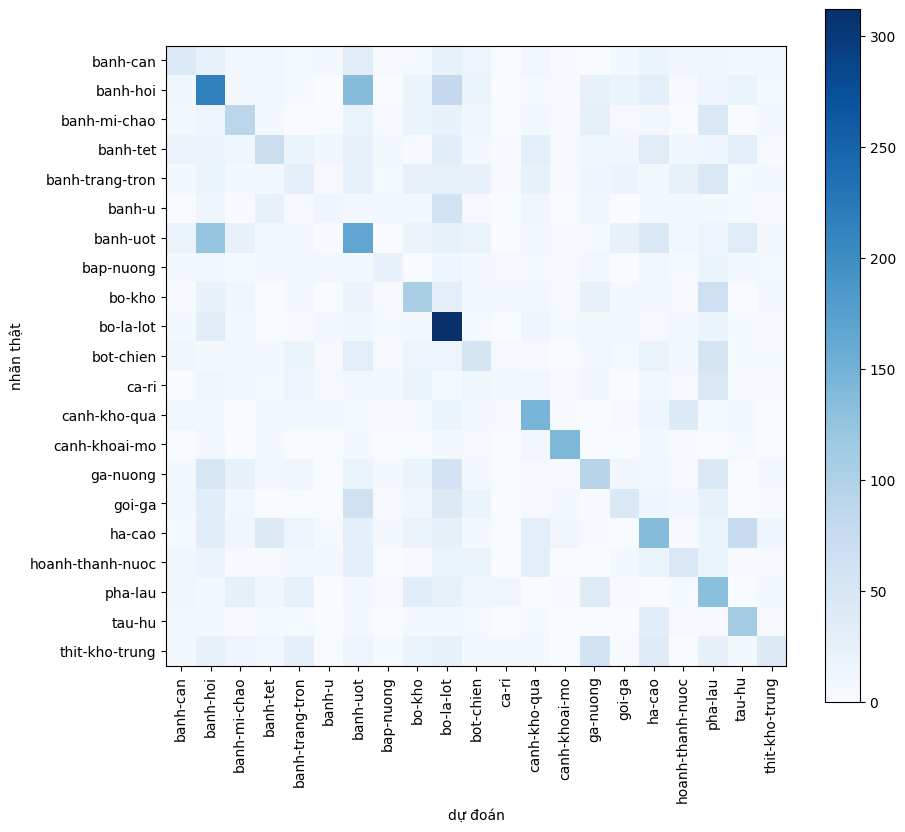

đã lưu /kaggle/working/outputs/confusion_matrix.png


In [6]:
import argparse
from pathlib import Path

import torch
import torch.nn as nn
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)

# data, model, engine đã được định nghĩa ở các ô trước nên không import lại


def four_metrics(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision_macro": p, "recall_macro": r, "f1_macro": f1}


def get_eval_args():
    p = argparse.ArgumentParser(description="Đánh giá LeNet-5 trên tập test")
    p.add_argument("--data_root", type=str, default=str(DATA_ROOT))
    default_ckpt = ("/kaggle/working/outputs/best.pt"
                    if Path("/kaggle/working").is_dir() else "outputs/best.pt")
    p.add_argument("--ckpt", type=str, default=default_ckpt)
    p.add_argument("--batch_size", type=int, default=BATCH)
    p.add_argument("--num_workers", type=int, default=2)
    args, _ = p.parse_known_args()
    return args


def save_confusion_matrix(cm, classes, path):
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(10, 9))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(classes)), classes, rotation=90)
    ax.set_yticks(range(len(classes)), classes)
    ax.set_xlabel("dự đoán"); ax.set_ylabel("nhãn thật")
    fig.colorbar(im)
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def eval_main():
    args = get_eval_args()
    data_root = Path(args.data_root)
    if not (data_root / "test").is_dir():
        raise FileNotFoundError(f"Không thấy thư mục 'test' trong {data_root}")
    if not Path(args.ckpt).is_file():
        raise FileNotFoundError(f"Không thấy checkpoint {args.ckpt}. Hãy chạy ô train trước.")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    ckpt = torch.load(args.ckpt, map_location=device)
    classes, img_size = ckpt["classes"], ckpt["img_size"]

    model = LeNet5(in_ch=3, img=img_size, num_classes=len(classes)).to(device)
    model.load_state_dict(ckpt["model"])

    test_dl, test_classes = build_test_loader(
        data_root, img_size, args.batch_size, args.num_workers)
    assert test_classes == classes, "thứ tự lớp ở test khác train"

    loss, acc, f1, y_true, y_pred = evaluate(
        model, test_dl, nn.CrossEntropyLoss(), device)
    print(f"checkpoint epoch {ckpt['epoch']} | test loss {loss:.4f}\n")

    # ===== 4 độ đo tổng hợp =====
    m = four_metrics(y_true, y_pred)
    print("=== KẾT QUẢ TRÊN TẬP TEST ===")
    for k, v in m.items():
        print(f"{k:>16}: {v:.4f}")
    print()

    # ===== Chi tiết theo từng lớp =====
    labels = list(range(len(classes)))
    print(classification_report(y_true, y_pred, labels=labels,
                                target_names=classes, digits=4, zero_division=0))

    out_path = Path(args.ckpt).parent / "confusion_matrix.png"
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    save_confusion_matrix(cm, classes, out_path)
    print("đã lưu", out_path)


eval_main()

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**

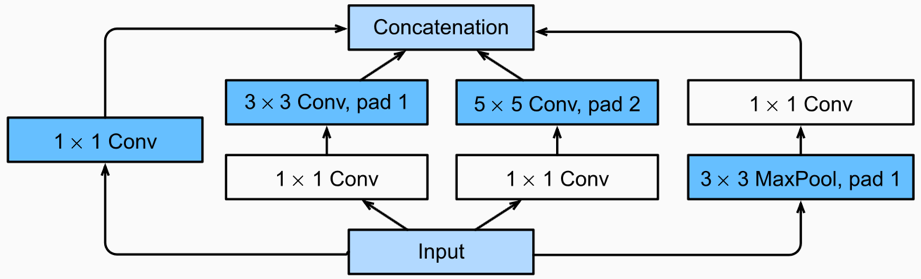

**GoogLeNet (Multi-branch Network)**

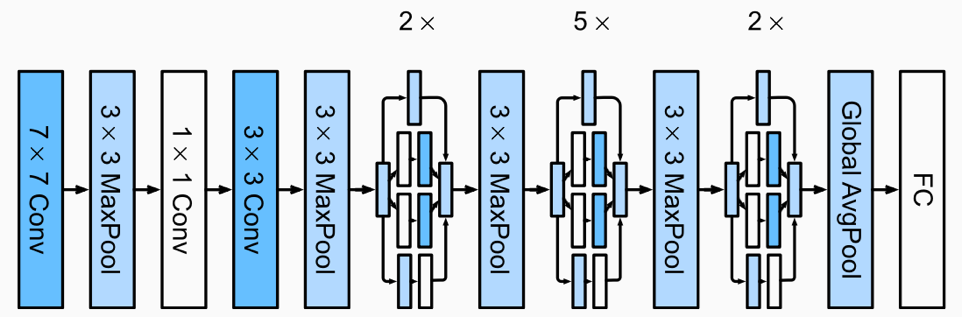

## **model GoogleNet**


In [7]:
import torch
import torch.nn as nn


class ConvBN(nn.Module):
    def __init__(self, cin, cout, **kw):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, bias=False, **kw)
        self.bn = nn.BatchNorm2d(cout)

    def forward(self, x):
        return torch.relu(self.bn(self.conv(x)))


class Inception(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = ConvBN(cin, c1, kernel_size=1)
        self.b2 = nn.Sequential(ConvBN(cin, c3r, kernel_size=1),
                                ConvBN(c3r, c3, kernel_size=3, padding=1))
        self.b3 = nn.Sequential(ConvBN(cin, c5r, kernel_size=1),
                                ConvBN(c5r, c5, kernel_size=5, padding=2))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, 1, 1),
                                ConvBN(cin, cp, kernel_size=1))

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], 1)


class GoogLeNet(nn.Module):
    def __init__(self, in_ch=3, num_classes=21, dropout=0.4):
        super().__init__()
        self.stem = nn.Sequential(
            ConvBN(in_ch, 64, kernel_size=7, stride=2, padding=3),
            nn.MaxPool2d(3, 2, ceil_mode=True),
            ConvBN(64, 64, kernel_size=1),
            ConvBN(64, 192, kernel_size=3, padding=1),
            nn.MaxPool2d(3, 2, ceil_mode=True))
        self.i3 = nn.Sequential(Inception(192, 64, 96, 128, 16, 32, 32),
                                Inception(256, 128, 128, 192, 32, 96, 64),
                                nn.MaxPool2d(3, 2, ceil_mode=True))
        self.i4 = nn.Sequential(Inception(480, 192, 96, 208, 16, 48, 64),
                                Inception(512, 160, 112, 224, 24, 64, 64),
                                Inception(512, 128, 128, 256, 24, 64, 64),
                                Inception(512, 112, 144, 288, 32, 64, 64),
                                Inception(528, 256, 160, 320, 32, 128, 128),
                                nn.MaxPool2d(3, 2, ceil_mode=True))
        self.i5 = nn.Sequential(Inception(832, 256, 160, 320, 32, 128, 128),
                                Inception(832, 384, 192, 384, 48, 128, 128))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(1024, num_classes)

    def forward(self, x):
        x = self.i5(self.i4(self.i3(self.stem(x))))
        x = self.drop(self.pool(x).flatten(1))
        return self.fc(x)


# kiểm tra shape
_m = GoogLeNet(num_classes=21)
print(tuple(_m(torch.rand(2, 3, IMG_SIZE, IMG_SIZE)).shape), f"{n_params(_m):,} tham số")

(2, 21) 6,002,357 tham số


## **Train GoogleNet**

device: cuda | số lớp: 21 | train: 9040 | val: 1004
GoogLeNet: 6,002,357 tham số


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.8725/0.1475  val 2.7464/0.1564  P 0.0883  R 0.1234  F1 0.0915  *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.7034/0.1835  val 3.0994/0.1863  P 0.1715  R 0.1526  F1 0.1182  *


...

epoch 18  train 1.5998/0.4996  val 1.5184/0.5249  P 0.5274  R 0.5071  F1 0.5059  *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19  train 1.5449/0.5150  val 1.7323/0.4811  P 0.4888  R 0.4351  F1 0.4350


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20  train 1.4982/0.5238  val 1.6588/0.4851  P 0.4896  R 0.4464  F1 0.4425


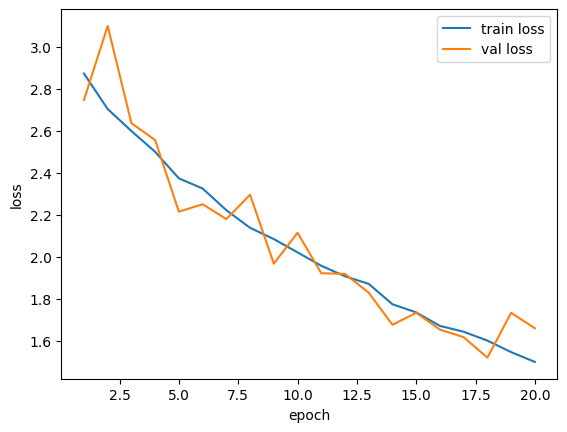


best val macro-F1: 0.5059 -> /kaggle/working/outputs_googlenet/best.pt


In [8]:
import csv
from pathlib import Path
import torch
import torch.nn as nn

GN_OUT = Path("/kaggle/working/outputs_googlenet") if Path("/kaggle/working").is_dir() \
    else Path("outputs_googlenet")


def train_googlenet(epochs=20, lr=1e-3):
    GN_OUT.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    train_dl, val_dl, classes = build_train_val_loaders(DATA_ROOT, IMG_SIZE, BATCH, seed=SEED)
    print(f"device: {device} | số lớp: {len(classes)} | "
          f"train: {len(train_dl.dataset)} | val: {len(val_dl.dataset)}")

    model = GoogLeNet(in_ch=3, num_classes=len(classes)).to(device)
    print(f"GoogLeNet: {n_params(model):,} tham số")

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history, best_f1 = [], -1.0
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, va_f1, yt, yp = evaluate(model, val_dl, criterion, device)
        vm = four_metrics(yt, yp)
        history.append(dict(epoch=ep, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc,
                            val_precision=vm["precision_macro"],
                            val_recall=vm["recall_macro"],
                            val_f1=vm["f1_macro"]))
        mark = ""
        if va_f1 > best_f1:
            best_f1 = va_f1
            torch.save({"model": model.state_dict(), "classes": classes,
                        "img_size": IMG_SIZE, "epoch": ep}, GN_OUT / "best.pt")
            mark = "  *"
        print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}  "
              f"val {va_loss:.4f}/{va_acc:.4f}  P {vm['precision_macro']:.4f}  "
              f"R {vm['recall_macro']:.4f}  F1 {va_f1:.4f}{mark}")

    with open(GN_OUT / "history.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=history[0].keys())
        w.writeheader()
        w.writerows(history)
    save_loss_curve(history, GN_OUT / "loss_curve.png")   # dùng lại hàm ở ô train bài 1
    print(f"\nbest val macro-F1: {best_f1:.4f} -> {GN_OUT / 'best.pt'}")


train_googlenet()

## **Evaluate GoogleNet**


checkpoint epoch 18 | test loss 1.7636

=== KẾT QUẢ GOOGLENET TRÊN TẬP TEST ===
        accuracy: 0.4563
 precision_macro: 0.4503
    recall_macro: 0.4509
        f1_macro: 0.4363

                  precision    recall  f1-score   support

        banh-can     0.3063    0.3444    0.3242       241
        banh-hoi     0.5542    0.5140    0.5333       607
    banh-mi-chao     0.4226    0.6332    0.5069       289
        banh-tet     0.6891    0.5055    0.5832       364
 banh-trang-tron     0.2484    0.1262    0.1674       309
          banh-u     0.2982    0.3693    0.3299       176
        banh-uot     0.4331    0.3179    0.3666       560
       bap-nuong     0.2959    0.2028    0.2407       143
          bo-kho     0.4273    0.5651    0.4866       338
       bo-la-lot     0.5007    0.8231    0.6226       458
       bot-chien     0.3412    0.5217    0.4126       276
           ca-ri     0.2319    0.2807    0.2540       171
    canh-kho-qua     0.5499    0.7414    0.6314       290
   can

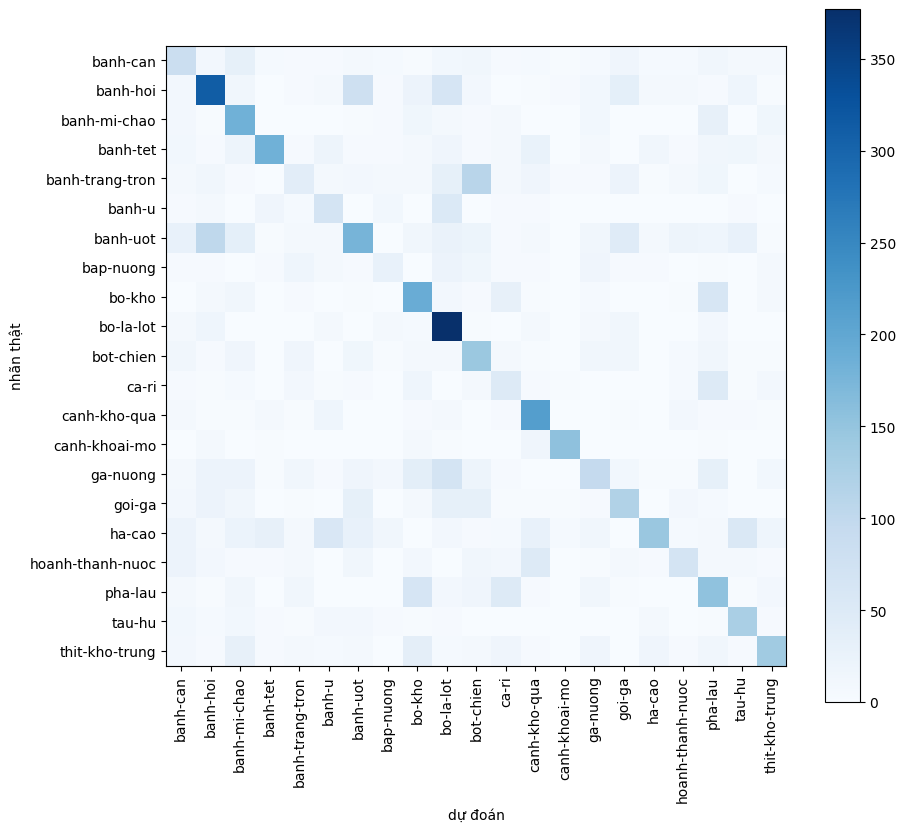

In [9]:
from sklearn.metrics import classification_report, confusion_matrix


def eval_googlenet():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(GN_OUT / "best.pt", map_location=device)
    classes, img_size = ckpt["classes"], ckpt["img_size"]

    model = GoogLeNet(in_ch=3, num_classes=len(classes)).to(device)
    model.load_state_dict(ckpt["model"])

    test_dl, test_classes = build_test_loader(DATA_ROOT, img_size, BATCH, 2)
    assert test_classes == classes, "thứ tự lớp ở test khác train"

    loss, acc, f1, y_true, y_pred = evaluate(model, test_dl, nn.CrossEntropyLoss(), device)
    print(f"checkpoint epoch {ckpt['epoch']} | test loss {loss:.4f}\n")

    m = four_metrics(y_true, y_pred)
    print("=== KẾT QUẢ GOOGLENET TRÊN TẬP TEST ===")
    for k, v in m.items():
        print(f"{k:>16}: {v:.4f}")
    print()

    labels = list(range(len(classes)))
    print(classification_report(y_true, y_pred, labels=labels,
                                target_names=classes, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    save_confusion_matrix(cm, classes, GN_OUT / "confusion_matrix.png")  # dùng lại hàm bài 1


eval_googlenet()

### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**

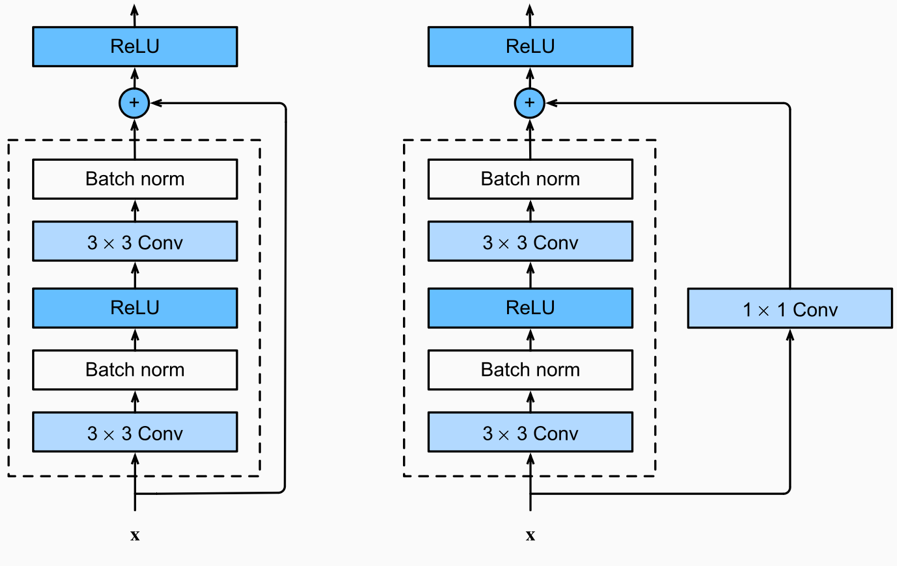

**ResNet**

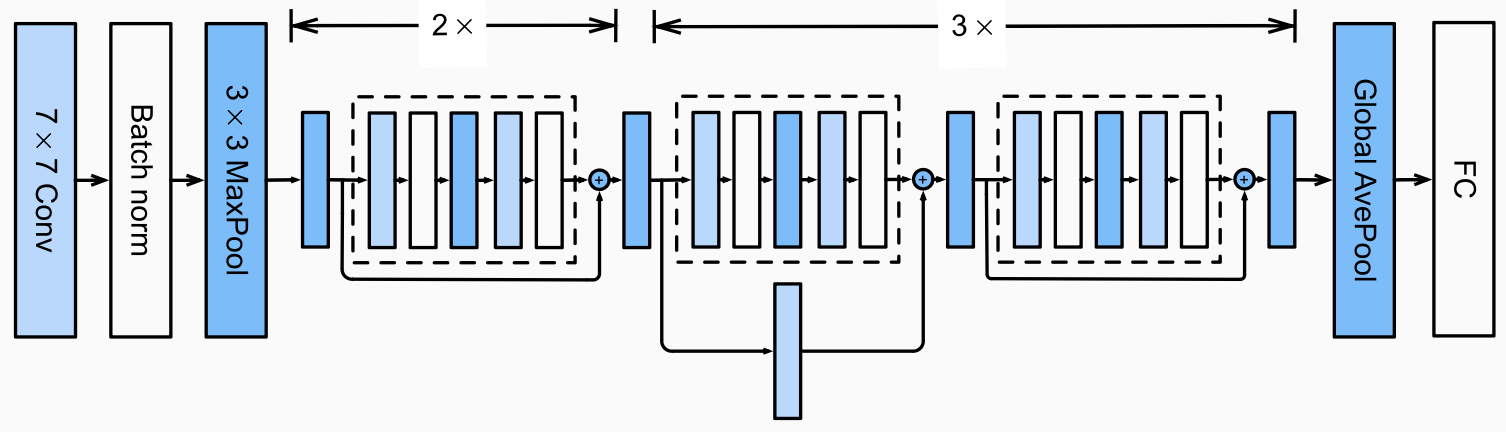

## **Model ResNet18**


In [10]:
import torch
import torch.nn as nn


class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Identity()
        if stride != 1 or cin != cout:        # khớp shape cho nhánh tắt
            self.shortcut = nn.Sequential(
                nn.Conv2d(cin, cout, 1, stride, bias=False),
                nn.BatchNorm2d(cout))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.shortcut(x))


class ResNet18(nn.Module):
    def __init__(self, in_ch=3, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_ch, 64, 7, 2, 3, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1))
        cfg = [(64, 64, 1), (64, 128, 2), (128, 256, 2), (256, 512, 2)]
        layers = []
        for cin, cout, s in cfg:
            layers += [BasicBlock(cin, cout, s), BasicBlock(cout, cout, 1)]
        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(self.pool(x).flatten(1))


# kiểm tra shape
_m = ResNet18(num_classes=21)
print(tuple(_m(torch.rand(2, 3, IMG_SIZE, IMG_SIZE)).shape), f"{n_params(_m):,} tham số")

(2, 21) 11,187,285 tham số


## **Train ResNet18**

device: cuda | số lớp: 21 | train: 9040 | val: 1004
ResNet-18: 11,187,285 tham số


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.7595/0.1733  val 3.0019/0.1633  P 0.1318  R 0.1524  F1 0.0954  *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.5034/0.2330  val 2.4469/0.2560  P 0.2024  R 0.2251  F1 0.1898  *


...

epoch 18  train 1.2322/0.5993  val 1.6683/0.5070  P 0.5357  R 0.4833  F1 0.4889


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19  train 1.1616/0.6238  val 1.6861/0.5159  P 0.5501  R 0.4803  F1 0.4813


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20  train 1.0929/0.6467  val 1.5727/0.5398  P 0.5659  R 0.5134  F1 0.5193  *


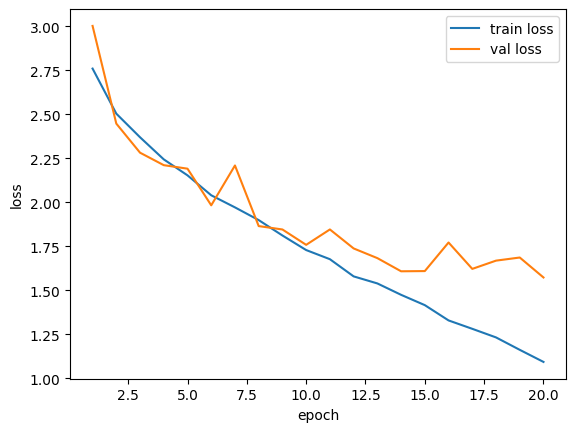


best val macro-F1: 0.5193 -> /kaggle/working/outputs_resnet18/best.pt


In [11]:
import csv
from pathlib import Path
import torch
import torch.nn as nn

RN_OUT = Path("/kaggle/working/outputs_resnet18") if Path("/kaggle/working").is_dir() \
    else Path("outputs_resnet18")


def train_resnet18(epochs=20, lr=1e-3):
    RN_OUT.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    train_dl, val_dl, classes = build_train_val_loaders(DATA_ROOT, IMG_SIZE, BATCH, seed=SEED)
    print(f"device: {device} | số lớp: {len(classes)} | "
          f"train: {len(train_dl.dataset)} | val: {len(val_dl.dataset)}")

    model = ResNet18(in_ch=3, num_classes=len(classes)).to(device)
    print(f"ResNet-18: {n_params(model):,} tham số")

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history, best_f1 = [], -1.0
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, va_f1, yt, yp = evaluate(model, val_dl, criterion, device)
        vm = four_metrics(yt, yp)
        history.append(dict(epoch=ep, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc,
                            val_precision=vm["precision_macro"],
                            val_recall=vm["recall_macro"],
                            val_f1=vm["f1_macro"]))
        mark = ""
        if va_f1 > best_f1:
            best_f1 = va_f1
            torch.save({"model": model.state_dict(), "classes": classes,
                        "img_size": IMG_SIZE, "epoch": ep}, RN_OUT / "best.pt")
            mark = "  *"
        print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}  "
              f"val {va_loss:.4f}/{va_acc:.4f}  P {vm['precision_macro']:.4f}  "
              f"R {vm['recall_macro']:.4f}  F1 {va_f1:.4f}{mark}")

    with open(RN_OUT / "history.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=history[0].keys())
        w.writeheader()
        w.writerows(history)
    save_loss_curve(history, RN_OUT / "loss_curve.png")
    print(f"\nbest val macro-F1: {best_f1:.4f} -> {RN_OUT / 'best.pt'}")


train_resnet18()

## **Evaluate ResNet18**

checkpoint epoch 20 | test loss 1.9335

=== KẾT QUẢ RESNET-18 TRÊN TẬP TEST ===
        accuracy: 0.4626
 precision_macro: 0.4792
    recall_macro: 0.4514
        f1_macro: 0.4483

                  precision    recall  f1-score   support

        banh-can     0.3934    0.3444    0.3673       241
        banh-hoi     0.5403    0.5189    0.5294       607
    banh-mi-chao     0.5000    0.6125    0.5505       289
        banh-tet     0.6980    0.4698    0.5616       364
 banh-trang-tron     0.4150    0.1974    0.2675       309
          banh-u     0.6829    0.3182    0.4341       176
        banh-uot     0.3817    0.3196    0.3479       560
       bap-nuong     0.4079    0.2168    0.2831       143
          bo-kho     0.4362    0.5059    0.4685       338
       bo-la-lot     0.6430    0.6725    0.6574       458
       bot-chien     0.3642    0.4130    0.3871       276
           ca-ri     0.2727    0.2281    0.2484       171
    canh-kho-qua     0.6642    0.6069    0.6342       290
   can

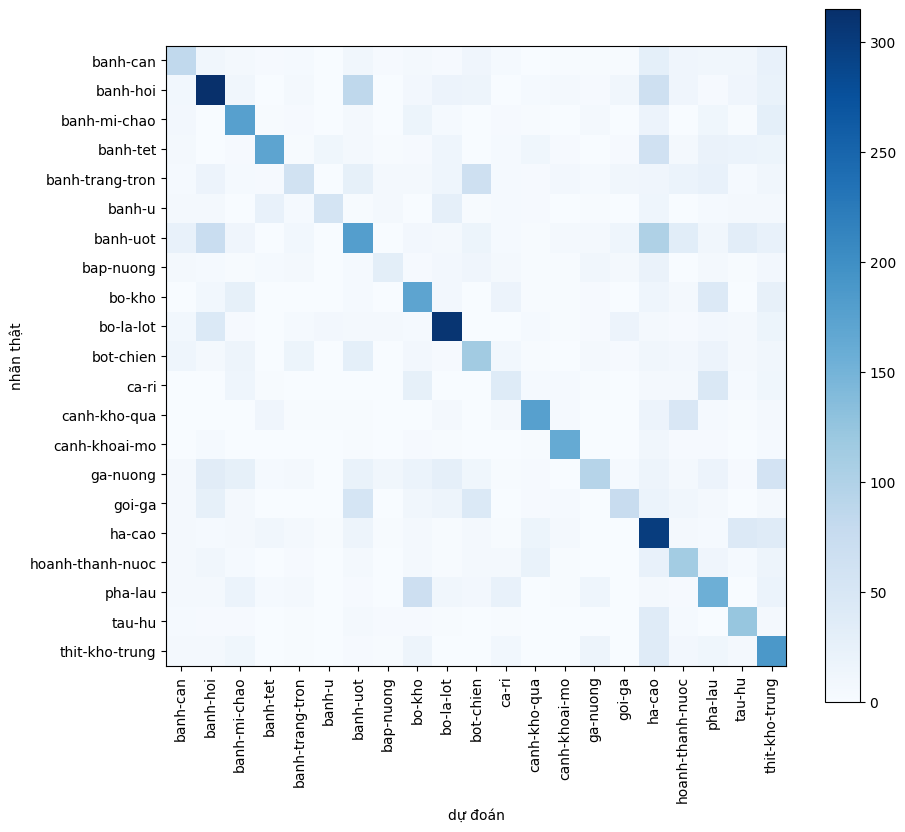

In [12]:
from sklearn.metrics import classification_report, confusion_matrix


def eval_resnet18():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(RN_OUT / "best.pt", map_location=device)
    classes, img_size = ckpt["classes"], ckpt["img_size"]

    model = ResNet18(in_ch=3, num_classes=len(classes)).to(device)
    model.load_state_dict(ckpt["model"])

    test_dl, test_classes = build_test_loader(DATA_ROOT, img_size, BATCH, 2)
    assert test_classes == classes, "thứ tự lớp ở test khác train"

    loss, acc, f1, y_true, y_pred = evaluate(model, test_dl, nn.CrossEntropyLoss(), device)
    print(f"checkpoint epoch {ckpt['epoch']} | test loss {loss:.4f}\n")

    m = four_metrics(y_true, y_pred)
    print("=== KẾT QUẢ RESNET-18 TRÊN TẬP TEST ===")
    for k, v in m.items():
        print(f"{k:>16}: {v:.4f}")
    print()

    labels = list(range(len(classes)))
    print(classification_report(y_true, y_pred, labels=labels,
                                target_names=classes, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    save_confusion_matrix(cm, classes, RN_OUT / "confusion_matrix.png")


eval_resnet18()

### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.

## **Model ResNet50 (Hugging Face)**

In [13]:
import torch
import torch.nn as nn
from transformers import AutoConfig, ResNetForImageClassification

HF_NAME = "microsoft/resnet-50"


class HFResNet50(nn.Module):
    def __init__(self, num_classes=21, pretrained=True):
        super().__init__()
        if pretrained:
            # thay đầu phân loại 1000 lớp ImageNet bằng đầu mới num_classes lớp
            self.m = ResNetForImageClassification.from_pretrained(
                HF_NAME, num_labels=num_classes, ignore_mismatched_sizes=True)
        else:
            cfg = AutoConfig.from_pretrained(HF_NAME, num_labels=num_classes)
            self.m = ResNetForImageClassification(cfg)

    def forward(self, x):
        return self.m(pixel_values=x).logits


# kiểm tra shape
_m = HFResNet50(num_classes=21)
print(tuple(_m(torch.rand(2, 3, 224, 224)).shape), f"{n_params(_m):,} tham số")

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

[transformers] You passed `num_labels=21` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

[transformers] ResNetForImageClassification LOAD REPORT from: microsoft/resnet-50
Key                 | Status   |                                                                                             
--------------------+----------+---------------------------------------------------------------------------------------------
classifier.1.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 2048]) vs model:torch.Size([21, 2048])
classifier.1.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([21])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


(2, 21) 23,551,061 tham số


## **Train ResNet50**

device: cuda | số lớp: 21 | train: 9040 | val: 1004


[transformers] You passed `num_labels=21` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

[transformers] ResNetForImageClassification LOAD REPORT from: microsoft/resnet-50
Key                 | Status   |                                                                                             
--------------------+----------+---------------------------------------------------------------------------------------------
classifier.1.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 2048]) vs model:torch.Size([21, 2048])
classifier.1.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([21])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


ResNet50 (HF): 23,551,061 tham số


...

epoch  8  train 0.3318/0.8965  val 0.3913/0.8785  P 0.8783  R 0.8733  F1 0.8729  *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  9  train 0.2911/0.9107  val 0.3724/0.8725  P 0.8659  R 0.8727  F1 0.8673


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 10  train 0.2469/0.9242  val 0.3599/0.8825  P 0.8894  R 0.8758  F1 0.8764  *


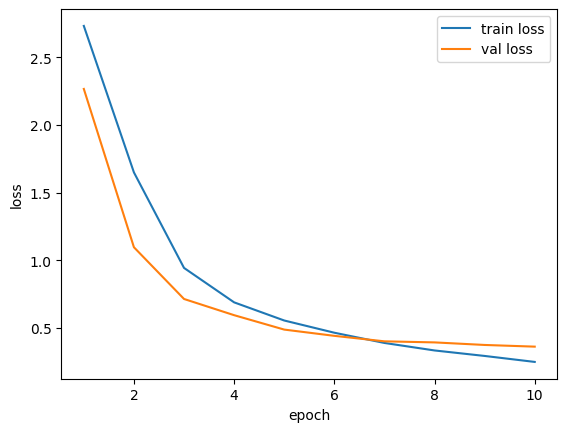


best val macro-F1: 0.8764 -> /kaggle/working/outputs_resnet50_hf/best.pt


In [14]:
import csv
from pathlib import Path
import torch
import torch.nn as nn

FT_SIZE = 224
FT_BATCH = 32
R50_OUT = Path("/kaggle/working/outputs_resnet50_hf") if Path("/kaggle/working").is_dir() \
    else Path("outputs_resnet50_hf")


def train_resnet50(epochs=10, lr=1e-4):
    R50_OUT.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    train_dl, val_dl, classes = build_train_val_loaders(
        DATA_ROOT, FT_SIZE, FT_BATCH, seed=SEED)
    print(f"device: {device} | số lớp: {len(classes)} | "
          f"train: {len(train_dl.dataset)} | val: {len(val_dl.dataset)}")

    model = HFResNet50(num_classes=len(classes)).to(device)
    print(f"ResNet50 (HF): {n_params(model):,} tham số")

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history, best_f1 = [], -1.0
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, va_f1, yt, yp = evaluate(model, val_dl, criterion, device)
        vm = four_metrics(yt, yp)
        history.append(dict(epoch=ep, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc,
                            val_precision=vm["precision_macro"],
                            val_recall=vm["recall_macro"],
                            val_f1=vm["f1_macro"]))
        mark = ""
        if va_f1 > best_f1:
            best_f1 = va_f1
            torch.save({"model": model.state_dict(), "classes": classes,
                        "img_size": FT_SIZE, "epoch": ep}, R50_OUT / "best.pt")
            mark = "  *"
        print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}  "
              f"val {va_loss:.4f}/{va_acc:.4f}  P {vm['precision_macro']:.4f}  "
              f"R {vm['recall_macro']:.4f}  F1 {va_f1:.4f}{mark}")

    with open(R50_OUT / "history.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=history[0].keys())
        w.writeheader()
        w.writerows(history)
    save_loss_curve(history, R50_OUT / "loss_curve.png")
    print(f"\nbest val macro-F1: {best_f1:.4f} -> {R50_OUT / 'best.pt'}")


train_resnet50()

## **Evaluate ResNet50**

[transformers] You passed `num_labels=21` which is incompatible to the `id2label` map of length `1000`.


checkpoint epoch 10 | test loss 0.5149

=== KẾT QUẢ RESNET50 (FINE-TUNE) TRÊN TẬP TEST ===
        accuracy: 0.8459
 precision_macro: 0.8467
    recall_macro: 0.8451
        f1_macro: 0.8427

                  precision    recall  f1-score   support

        banh-can     0.8088    0.9129    0.8577       241
        banh-hoi     0.8704    0.8633    0.8668       607
    banh-mi-chao     0.8896    0.9204    0.9048       289
        banh-tet     0.9822    0.7582    0.8558       364
 banh-trang-tron     0.9123    0.9094    0.9109       309
          banh-u     0.7692    0.9091    0.8333       176
        banh-uot     0.8022    0.7821    0.7920       560
       bap-nuong     0.9789    0.9720    0.9754       143
          bo-kho     0.7555    0.8136    0.7835       338
       bo-la-lot     0.9101    0.9279    0.9189       458
       bot-chien     0.8358    0.8116    0.8235       276
           ca-ri     0.6481    0.4094    0.5018       171
    canh-kho-qua     0.9510    0.9379    0.9444      

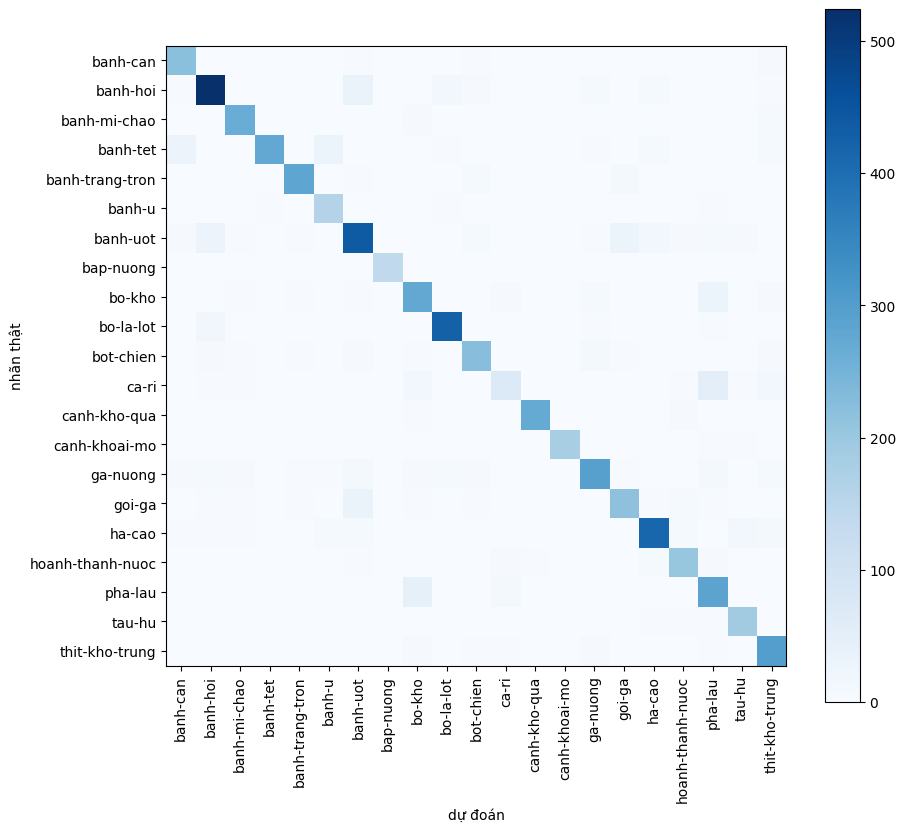

In [15]:
from sklearn.metrics import classification_report, confusion_matrix


def eval_resnet50():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(R50_OUT / "best.pt", map_location=device)
    classes, img_size = ckpt["classes"], ckpt["img_size"]

    # pretrained=False: chỉ dựng khung, trọng số lấy từ checkpoint đã fine-tune
    model = HFResNet50(num_classes=len(classes), pretrained=False).to(device)
    model.load_state_dict(ckpt["model"])

    test_dl, test_classes = build_test_loader(DATA_ROOT, img_size, FT_BATCH, 2)
    assert test_classes == classes, "thứ tự lớp ở test khác train"

    loss, acc, f1, y_true, y_pred = evaluate(model, test_dl, nn.CrossEntropyLoss(), device)
    print(f"checkpoint epoch {ckpt['epoch']} | test loss {loss:.4f}\n")

    m = four_metrics(y_true, y_pred)
    print("=== KẾT QUẢ RESNET50 (FINE-TUNE) TRÊN TẬP TEST ===")
    for k, v in m.items():
        print(f"{k:>16}: {v:.4f}")
    print()

    labels = list(range(len(classes)))
    print(classification_report(y_true, y_pred, labels=labels,
                                target_names=classes, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    save_confusion_matrix(cm, classes, R50_OUT / "confusion_matrix.png")


eval_resnet50()